In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the prepared dataset
df = pd.read_csv(
    "../data/processed/housing_preprocessed.csv",
    low_memory=False
)

print("Dataset shape:", df.shape)
display(df.head())
print("\nAvailable columns:")
print(df.columns.tolist())

Dataset shape: (10319, 69)


,prop_id,photo_url,medium_photo_url,preference,description,property_type,locality,transact_type,owntype,bedroom_num,...,location,builtup_sqft,super_sqft,furnishing_attributes,latitude,longitude,price_lakhs,price_per_sqft,log_price,locality_grouped
0,O71585872,https://mediacdn.99acres.com/media1/22409/13/4...,https://mediacdn.99acres.com/media1/22409/13/4...,S,4 bhk flat for resale in alpha corp gurgaon one,Residential Apartment,Sector 84 Gurgaon,1.0,1,4.0,...,"{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",NaN,NaN,NaN,28.403547,76.967789,263.00,NaN,5.575949,Sector 84 Gurgaon
1,T71585466,https://mediacdn.99acres.com/media1/22425/6/44...,https://mediacdn.99acres.com/media1/22425/6/44...,S,"Explore dlf ultima, an upscale ready-To-Move h...",Residential Apartment,Sector 81 Gurgaon,1.0,1,4.0,...,"{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",NaN,NaN,NaN,28.387365,76.947583,360.00,NaN,5.888878,Sector 81 Gurgaon
2,D71549524,https://mediacdn.99acres.com/media1/22386/13/4...,https://mediacdn.99acres.com/media1/22386/13/4...,R,A 3 bhk flat for rent in sector 66 gurgaon clo...,Residential Apartment,Sector 66 Gurgaon,NaN,0,3.0,...,"{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",1920.00,NaN,NaN,28.397429,77.053882,0.85,44.270833,0.615186,Sector 66 Gurgaon
3,I71493958,https://mediacdn.99acres.com/media1/22353/14/4...,https://mediacdn.99acres.com/media1/22353/14/4...,S,Looking for a 3 bhk property for purchase in g...,Residential Apartment,Sector 112 Gurgaon,1.0,1,3.0,...,"{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",2225.56,NaN,NaN,28.520340,77.018861,385.00,17299.016877,5.955837,Sector 112 Gurgaon
4,H71479412,https://mediacdn.99acres.com/media1/22352/4/44...,https://mediacdn.99acres.com/media1/22352/4/44...,R,This 4 bhk flat in sector 104 gurgaon is avail...,Residential Apartment,Sector 104 Gurgaon,NaN,0,3.0,...,"{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",NaN,NaN,NaN,28.479532,76.993720,0.40,NaN,0.336472,Sector 104 Gurgaon



Available columns:
['prop_id', 'photo_url', 'medium_photo_url', 'preference', 'description', 'property_type', 'locality', 'transact_type', 'owntype', 'bedroom_num', 'bathroom_num', 'balcony_num', 'price_per_unit_area', 'furnish', 'facing', 'age', 'floor_num', 'total_floor', 'features', 'register_date', 'prop_name', 'min_price', 'max_price', 'price_sqft', 'listing', 'building_id', 'carpet_sqft', 'superbuiltup_sqft', 'brokerage', 'map_details', 'fsl_data', 'min_area_sqft', 'max_area_sqft', 'formatted', 'amenities', 'top_usps', 'pd_url', 'expiry_date', 'group_name', 'area', 'price', 'prop_heading', 'prop_details_url', 'class_heading', 'class_label', 'secondary_tags', 'property_images', 'thumbnail_images', 'total_landmark_count', 'formatted_landmark_details', 'contact_name', 'contact_company_name', 'dealer_photo_url', 'society_name', 'building_name', 'locality_wo_city', 'profile', 'xid', 'metadata', 'location', 'builtup_sqft', 'super_sqft', 'furnishing_attributes', 'latitude', 'longitude'

In [3]:
# Check target and transaction columns
for col in ["price", "price_lakhs", "transact_type"]:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print(df[col].head(10))
        print("Missing values:", df[col].isna().sum())
    else:
        print(f"\n{col} is not present.")


--- price ---
0    2.63 Cr
1     3.6 Cr
2     85,000
3    3.85 Cr
4     40,000
5    1.95 Cr
6     45,000
7    1.62 Cr
8    2.17 Cr
9     2.2 Cr
Name: price, dtype: str
Missing values: 0

--- price_lakhs ---
0    263.00
1    360.00
2      0.85
3    385.00
4      0.40
5    195.00
6      0.45
7    162.00
8    217.00
9    220.00
Name: price_lakhs, dtype: float64
Missing values: 27

--- transact_type ---
0    1.0
1    1.0
2    NaN
3    1.0
4    NaN
5    1.0
6    NaN
7    1.0
8    1.0
9    1.0
Name: transact_type, dtype: float64
Missing values: 543


In [4]:
if "transact_type" in df.columns:
    display(
        df["transact_type"]
        .value_counts(dropna=False)
        .to_frame("Listing_Count")
    )

,Listing_Count
transact_type,
1.0,9764
NaN,543
2.0,12


In [5]:
# EXAMPLE ONLY: Replace these values with the categories
# verified in your dataset.
sale_types = ["New Property", "Resale"]

if "transact_type" not in df.columns:
    raise ValueError("The transact_type column is missing.")

df["transact_type"] = df["transact_type"].astype("string").str.strip()

df = df[
    df["transact_type"].isin(sale_types)
].copy()

print("Rows after sale-listing filter:", len(df))

Rows after sale-listing filter: 0


In [6]:
if "price_lakhs" not in df.columns:
    raise ValueError(
        "price_lakhs is missing. Create and verify it in the preprocessing notebook first."
    )

df["price_lakhs"] = pd.to_numeric(
    df["price_lakhs"],
    errors="coerce"
)

# Keep rows with valid, positive target prices
df = df[
    df["price_lakhs"].notna() &
    (df["price_lakhs"] > 0)
].copy()

print("Rows with valid target prices:", len(df))
print("Missing target prices:", df["price_lakhs"].isna().sum())
print("Minimum price (lakhs):", df["price_lakhs"].min())
print("Maximum price (lakhs):", df["price_lakhs"].max())

Rows with valid target prices: 0
Missing target prices: 0
Minimum price (lakhs): nan
Maximum price (lakhs): nan


In [7]:
candidate_features = [
    "property_type",
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "carpet_sqft",
    "builtup_sqft",
    "superbuiltup_sqft",
    "age",
    "locality_grouped",
    "latitude",
    "longitude"
]

# Keep only columns that exist in the dataset
features = [
    col for col in candidate_features
    if col in df.columns
]

target = "price_lakhs"

print("Selected features:")
print(features)

if not features:
    raise ValueError("No selected features exist in the dataset.")

if "property_type" not in features:
    print("Warning: property_type is unavailable.")

if "locality_grouped" not in features:
    print("Warning: locality_grouped is unavailable.")

Selected features:
['property_type', 'bedroom_num', 'bathroom_num', 'balcony_num', 'carpet_sqft', 'builtup_sqft', 'superbuiltup_sqft', 'age', 'locality_grouped', 'latitude', 'longitude']


In [8]:
categorical_features = [
    col for col in features
    if (
        pd.api.types.is_object_dtype(df[col]) or
        isinstance(df[col].dtype, pd.CategoricalDtype) or
        pd.api.types.is_string_dtype(df[col])
    )
]

numeric_features = [
    col for col in features
    if col not in categorical_features
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['bedroom_num', 'bathroom_num', 'balcony_num', 'carpet_sqft', 'builtup_sqft', 'superbuiltup_sqft', 'age', 'latitude', 'longitude']
Categorical features: ['property_type', 'locality_grouped']


In [9]:
X = df[features].copy()
y = df[target].copy()

# Split before fitting any imputers, encoders, or scalers
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

ValueError: With n_samples=0, test_size=0.2 and train_size=None, the resulting train set will be empty. Adjust any of the aforementioned parameters.

In [10]:
print("Dataset shape:", df.shape)
print("Number of rows:", len(df))

print("\nTarget column exists:", "price_lakhs" in df.columns)

if "price_lakhs" in df.columns:
    print("\nTarget summary:")
    print(df["price_lakhs"].describe())
    print("\nMissing target values:", df["price_lakhs"].isna().sum())

if "transact_type" in df.columns:
    print("\nTransaction types:")
    print(df["transact_type"].value_counts(dropna=False))

Dataset shape: (0, 69)
Number of rows: 0

Target column exists: True

Target summary:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: price_lakhs, dtype: float64

Missing target values: 0

Transaction types:
Series([], Name: count, dtype: int64[pyarrow])


In [11]:
sale_types = ["New Property", "Resale"]

df = df[
    df["transact_type"].isin(sale_types)
].copy()

In [12]:
df_check = pd.read_csv(
    "../data/processed/housing_preprocessed.csv",
    low_memory=False
)

print("Saved dataset shape:", df_check.shape)

if "transact_type" in df_check.columns:
    print("\nActual transaction types:")
    print(df_check["transact_type"].value_counts(dropna=False))
else:
    print("transact_type column not found.")

Saved dataset shape: (10319, 69)

Actual transaction types:
transact_type
1.0    9764
NaN     543
2.0      12
Name: count, dtype: int64


In [13]:
if "price_lakhs" not in df.columns:
    raise ValueError(
        "price_lakhs is missing. Verify the price conversion first."
    )

df["price_lakhs"] = pd.to_numeric(
    df["price_lakhs"],
    errors="coerce"
)

print("Rows before target filtering:", len(df))
print("Valid target prices:", df["price_lakhs"].notna().sum())
print("Missing target prices:", df["price_lakhs"].isna().sum())

display(df["price_lakhs"].describe())

Rows before target filtering: 0
Valid target prices: 0
Missing target prices: 0


count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: price_lakhs, dtype: float64

In [14]:
df = df[
    df["price_lakhs"].notna() &
    (df["price_lakhs"] > 0)
].copy()

print("Rows remaining:", len(df))

if df.empty:
    raise ValueError(
        "No valid target prices remain. Check the price conversion."
    )

Rows remaining: 0


ValueError: No valid target prices remain. Check the price conversion.

In [15]:
import pandas as pd
import numpy as np
import re

# Reload the dataset to recover rows removed by the previous filter
df = pd.read_csv(
    "../data/processed/housing_preprocessed.csv",
    low_memory=False
)

print("Dataset shape:", df.shape)
print("\nAvailable price columns:")

print([col for col in df.columns if "price" in col.lower()])

Dataset shape: (10319, 69)

Available price columns:
['price_per_unit_area', 'min_price', 'max_price', 'price_sqft', 'price', 'price_lakhs', 'price_per_sqft', 'log_price']


In [16]:
print("Original price samples:")

display(df["price"].head(20))

print("\nOriginal price data type:")
print(df["price"].dtype)

print("\nExisting price_lakhs values:")

if "price_lakhs" in df.columns:
    display(df["price_lakhs"].head(20))
    print("Missing values:", df["price_lakhs"].isna().sum())
else:
    print("price_lakhs does not exist.")

Original price samples:


0     2.63 Cr
1      3.6 Cr
2      85,000
3     3.85 Cr
4      40,000
5     1.95 Cr
6      45,000
7     1.62 Cr
8     2.17 Cr
9      2.2 Cr
10    4.16 Cr
11     7.5 Cr
12     1.6 Cr
13     70,000
14     3.5 Cr
15    2.58 Cr
16     4.5 Cr
17    1.55 Cr
18     1.9 Cr
19     1.9 Cr
Name: price, dtype: str


Original price data type:
str

Existing price_lakhs values:


0     263.00
1     360.00
2       0.85
3     385.00
4       0.40
5     195.00
6       0.45
7     162.00
8     217.00
9     220.00
10    416.00
11    750.00
12    160.00
13      0.70
14    350.00
15    258.00
16    450.00
17    155.00
18    190.00
19    190.00
Name: price_lakhs, dtype: float64

Missing values: 27


In [17]:
def convert_price_to_lakhs(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower()
    text = text.replace(",", "").replace("₹", "").strip()

    if not text:
        return np.nan

    try:
        # Crore to lakh
        match = re.fullmatch(
            r"(\d+(?:\.\d+)?)\s*(?:crores?|cr)",
            text
        )
        if match:
            return float(match.group(1)) * 100

        # Lakh to lakh
        match = re.fullmatch(
            r"(\d+(?:\.\d+)?)\s*(?:lakhs?|lacs?|lac|l)",
            text
        )
        if match:
            return float(match.group(1))

        # Plain number: only interpret as rupees if verified
        match = re.fullmatch(r"\d+(?:\.\d+)?", text)
        if match:
            amount = float(text)

            # Assumption: unlabelled values are rupees
            # Use only after verifying the source convention.
            return amount / 100000

        return np.nan

    except (ValueError, TypeError):
        return np.nan


df["price_lakhs"] = df["price"].apply(convert_price_to_lakhs)

print("Converted prices:")
display(df[["price", "price_lakhs"]].head(20))

print("\nValid converted prices:", df["price_lakhs"].notna().sum())
print("Missing converted prices:", df["price_lakhs"].isna().sum())

Converted prices:


,price,price_lakhs
0,2.63 Cr,263.00
1,3.6 Cr,360.00
2,"85,000",0.85
3,3.85 Cr,385.00
4,"40,000",0.40
5,1.95 Cr,195.00
6,"45,000",0.45
7,1.62 Cr,162.00
8,2.17 Cr,217.00
9,2.2 Cr,220.00



Valid converted prices: 10292
Missing converted prices: 27


In [18]:
print(df["price_lakhs"].describe())

print(
    "\nPositive prices:",
    (df["price_lakhs"] > 0).sum()
)

display(
    df.loc[
        df["price_lakhs"].notna(),
        ["price", "price_lakhs"]
    ].head(20)
)

count    10292.000000
mean       320.385679
std        562.495265
min          0.100000
25%        136.000000
50%        216.000000
75%        373.250000
max      29000.000000
Name: price_lakhs, dtype: float64

Positive prices: 10292


,price,price_lakhs
0,2.63 Cr,263.00
1,3.6 Cr,360.00
2,"85,000",0.85
3,3.85 Cr,385.00
4,"40,000",0.40
5,1.95 Cr,195.00
6,"45,000",0.45
7,1.62 Cr,162.00
8,2.17 Cr,217.00
9,2.2 Cr,220.00


In [19]:
df = df.loc[
    df["price_lakhs"].notna() &
    (df["price_lakhs"] > 0)
].copy()

print("Rows remaining:", len(df))

if df.empty:
    raise ValueError(
        "No valid sale prices remain. Check the original price values."
    )

Rows remaining: 10292


In [20]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(
    output_dir / "housing_preprocessed.csv",
    index=False
)

print("Corrected dataset saved successfully.")
print("Dataset shape:", df.shape)

Corrected dataset saved successfully.
Dataset shape: (10292, 69)


In [21]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/processed/housing_preprocessed.csv",
    low_memory=False
)

print("Dataset shape:", df.shape)
print("\nTransaction types:")
print(df["transact_type"].value_counts(dropna=False))

print("\nPrice summary:")
print(df["price_lakhs"].describe())

Dataset shape: (10292, 69)

Transaction types:
transact_type
1.0    9742
NaN     543
2.0       7
Name: count, dtype: int64

Price summary:
count    10292.000000
mean       320.385679
std        562.495265
min          0.100000
25%        136.000000
50%        216.000000
75%        373.250000
max      29000.000000
Name: price_lakhs, dtype: float64


In [22]:
# Compare transaction codes with listing preferences
display(
    pd.crosstab(
        df["transact_type"],
        df["preference"],
        dropna=False
    )
)

# Inspect representative records
display(
    df[
        ["price", "price_lakhs", "transact_type", "preference"]
    ].head(30)
)

preference,R,S
transact_type,,
1.0,0,9742
2.0,0,7
NaN,540,3


,price,price_lakhs,transact_type,preference
0,2.63 Cr,263.00,1.0,S
1,3.6 Cr,360.00,1.0,S
2,"85,000",0.85,NaN,R
3,3.85 Cr,385.00,1.0,S
4,"40,000",0.40,NaN,R
5,1.95 Cr,195.00,1.0,S
6,"45,000",0.45,NaN,R
7,1.62 Cr,162.00,1.0,S
8,2.17 Cr,217.00,1.0,S
9,2.2 Cr,220.00,1.0,S


In [23]:
# Keep only sale listings
df["preference"] = (
    df["preference"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df = df[df["preference"] == "S"].copy()

print("Sale listings:", len(df))
print("\nPreference values:")
print(df["preference"].value_counts(dropna=False))

print("\nTransaction type distribution:")
print(df["transact_type"].value_counts(dropna=False))

Sale listings: 9752

Preference values:
preference
S    9752
Name: count, dtype: int64[pyarrow]

Transaction type distribution:
transact_type
1.0    9742
2.0       7
NaN       3
Name: count, dtype: int64


In [24]:
# Ensure the target column is numeric
df["price_lakhs"] = pd.to_numeric(
    df["price_lakhs"],
    errors="coerce"
)

rows_before = len(df)

# Remove missing, zero, and negative prices
df = df[
    df["price_lakhs"].notna() &
    (df["price_lakhs"] > 0)
].copy()

print("Sale listings before price filtering:", rows_before)
print("Sale listings after price filtering:", len(df))
print("Missing target prices:", df["price_lakhs"].isna().sum())
print("Minimum price (lakhs):", df["price_lakhs"].min())
print("Median price (lakhs):", df["price_lakhs"].median())
print("Maximum price (lakhs):", df["price_lakhs"].max())

if df.empty:
    raise ValueError("No valid sale prices remain. Check price conversion.")

Sale listings before price filtering: 9752
Sale listings after price filtering: 9752
Missing target prices: 0
Minimum price (lakhs): 1.0
Median price (lakhs): 225.0
Maximum price (lakhs): 29000.0


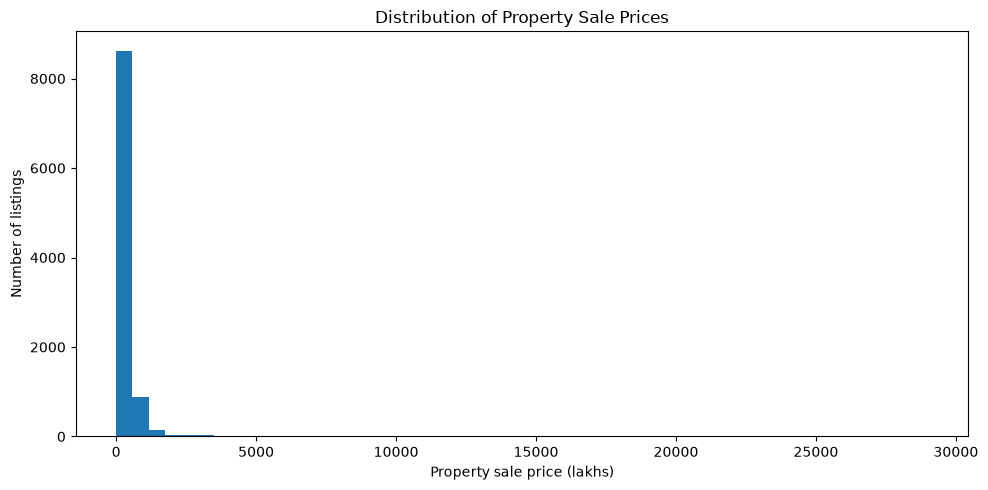

,price_lakhs
count,9752.000000
mean,338.084897
std,572.670662
min,1.000000
1%,29.945900
5%,61.550000
25%,150.000000
50%,225.000000
75%,382.500000
95%,890.000000


In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df["price_lakhs"], bins=50)
plt.xlabel("Property sale price (lakhs)")
plt.ylabel("Number of listings")
plt.title("Distribution of Property Sale Prices")
plt.tight_layout()
plt.show()

display(
    df["price_lakhs"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .to_frame()
)

In [28]:
# Display the 20 cheapest sale listings
print("20 Cheapest Sale Listings:")

display(
    df.sort_values("price_lakhs", ascending=True)[
        ["price", "price_lakhs", "property_type",
         "bedroom_num", "locality_grouped"]
    ].head(20)
)

# Display the 20 most expensive sale listings
print("\n20 Most Expensive Sale Listings:")

display(
    df.sort_values("price_lakhs", ascending=False)[
        ["price", "price_lakhs", "property_type",
         "bedroom_num", "locality_grouped"]
    ].head(20)
)

20 Cheapest Sale Listings:


,price,price_lakhs,property_type,bedroom_num,locality_grouped
8631,1 L,1.00,Residential Land,3.0,Sector 92 Gurgaon
1499,4.5 L,4.50,Residential Land,3.0,Other
6579,8.5 L,8.50,Residential Apartment,1.0,Sector 70A Gurgaon
1504,8.5 L,8.50,Residential Land,3.0,Other
8484,9 L,9.00,Residential Land,3.0,Other
6607,9.5 L,9.50,Residential Apartment,1.0,Sector 77 Gurgaon
2395,11.76 L,11.76,Residential Land,3.0,Sector 92 Gurgaon
4867,12.6 L,12.60,Residential Land,3.0,Other
3379,16 L,16.00,Residential Apartment,1.0,Sector 111 Gurgaon
5758,16 L,16.00,Residential Apartment,1.0,Other



20 Most Expensive Sale Listings:


,price,price_lakhs,property_type,bedroom_num,locality_grouped
8869,290 Cr,29000.0,Independent/Builder Floor,4.0,DLF Phase 3
4778,225 Cr,22500.0,Independent/Builder Floor,4.0,Sector 92 Gurgaon
1280,160 Cr,16000.0,Residential Land,3.0,Sohna
614,150 Cr,15000.0,Residential Apartment,10.0,Sector 42 Gurgaon
2601,55 Cr,5500.0,Residential Apartment,5.0,Sector 42 Gurgaon
5291,55 Cr,5500.0,Residential Apartment,4.0,Sector 42 Gurgaon
5589,55 Cr,5500.0,Residential Apartment,4.0,Sector 42 Gurgaon
7380,54 Cr,5400.0,Residential Apartment,4.0,Sector 106 Gurgaon
4069,50 Cr,5000.0,Residential Apartment,4.0,Sector 42 Gurgaon
8547,50 Cr,5000.0,Residential Apartment,5.0,Sector 42 Gurgaon


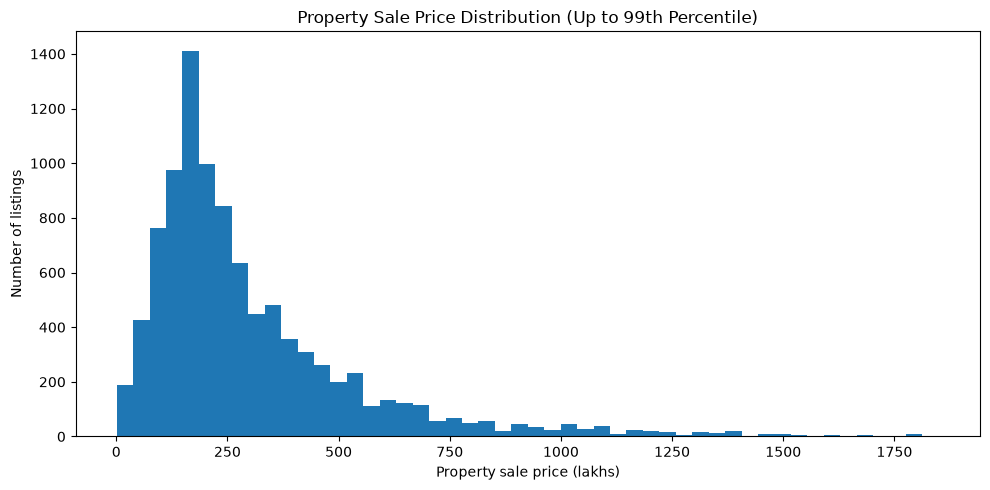

99th percentile: ₹1850.00 lakhs
Listings excluded from this plot only: 96


In [29]:
import matplotlib.pyplot as plt

# Calculate the 99th percentile
p99 = df["price_lakhs"].quantile(0.99)

# Select prices within the 99th percentile for visualization
prices_for_plot = df.loc[
    df["price_lakhs"] <= p99,
    "price_lakhs"
]

plt.figure(figsize=(10, 5))
plt.hist(prices_for_plot, bins=50)

plt.xlabel("Property sale price (lakhs)")
plt.ylabel("Number of listings")
plt.title("Property Sale Price Distribution (Up to 99th Percentile)")

plt.tight_layout()
plt.show()

print(f"99th percentile: ₹{p99:.2f} lakhs")
print(f"Listings excluded from this plot only: {len(df) - len(prices_for_plot)}")

In [30]:
price_ranges = pd.cut(
    df["price_lakhs"],
    bins=[0, 10, 25, 50, 100, 250, 500, 1000, 5000, float("inf")],
    labels=[
        "Under ₹10 lakh",
        "₹10–25 lakh",
        "₹25–50 lakh",
        "₹50 lakh–1 crore",
        "₹1–2.5 crore",
        "₹2.5–5 crore",
        "₹5–10 crore",
        "₹10–50 crore",
        "Above ₹50 crore"
    ],
    right=False
)

print(price_ranges.value_counts(sort=False))

price_lakhs
Under ₹10 lakh         6
₹10–25 lakh           42
₹25–50 lakh          285
₹50 lakh–1 crore     698
₹1–2.5 crore        4337
₹2.5–5 crore        2797
₹5–10 crore         1201
₹10–50 crore         375
Above ₹50 crore       11
Name: count, dtype: int64


In [31]:
candidate_features = [
    "property_type",
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "carpet_sqft",
    "builtup_sqft",
    "superbuiltup_sqft",
    "age",
    "locality_grouped",
    "latitude",
    "longitude"
]

# Use only columns that actually exist
features = [
    col for col in candidate_features
    if col in df.columns
]

target = "price_lakhs"

X = df[features].copy()
y = df[target].copy()

print("Features selected:", features)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature data types:")
print(X.dtypes)

print("\nMissing values in each feature:")
print(X.isna().sum().sort_values(ascending=False))

Features selected: ['property_type', 'bedroom_num', 'bathroom_num', 'balcony_num', 'carpet_sqft', 'builtup_sqft', 'superbuiltup_sqft', 'age', 'locality_grouped', 'latitude', 'longitude']
Feature matrix shape: (9752, 11)
Target shape: (9752,)

Feature data types:
property_type            str
bedroom_num          float64
bathroom_num           int64
balcony_num          float64
carpet_sqft          float64
builtup_sqft         float64
superbuiltup_sqft    float64
age                    int64
locality_grouped         str
latitude             float64
longitude            float64
dtype: object

Missing values in each feature:
builtup_sqft         7254
carpet_sqft          3834
superbuiltup_sqft    3567
bathroom_num            0
bedroom_num             0
property_type           0
balcony_num             0
age                     0
locality_grouped        0
latitude                0
longitude               0
dtype: int64
